In [27]:
from pystac_client import Client
import stackstac
import osmnx as ox
import geopandas as gpd
import rioxarray as rxr
import matplotlib.pyplot as plt
import numpy as np
from shapely import box
from shapely.affinity import scale
import xarray as xr
import time
import rasterio
import shapely

In [28]:
def sieve_until_stable(a, size, connectivity=8, max_passes=10, mask=None):
    for _ in range(max_passes):
        out = rasterio.features.sieve(a, size=size, connectivity=connectivity, mask=mask)
        if np.array_equal(out, a):
            return out
        a = out
    return a

In [29]:
def load(da, tries=3):
    for attempt in range(tries):
        try:
            return da.compute()
        except RuntimeError as e:
            if attempt == tries - 1:
                raise
            print(f'read failed ({str(e)[:80]}...), retrying')
            time.sleep(5 * (attempt + 1))

In [30]:
# get the boundary polygon for Le Porge, France
aoi = ox.geocoder.geocode_to_gdf('Porge, France')
aoi_geom = aoi.geometry
bbox = list(scale(box(*aoi_geom[0].bounds), xfact=3, yfact=3).bounds) # have to zoom out a few times to get the whole extent of the burn

In [31]:
URL = 'https://earth-search.aws.element84.com/v1'
COLLECTION = 'sentinel-2-c1-l2a'
DATETIME = '2026-06-01/2026-09-30'
catalog = Client.open(URL)
items = catalog.search(
    collections=[COLLECTION],
    bbox=bbox,
    datetime=DATETIME,
    query={'eo:cloud_cover': {'lt': 20}},
    sortby='properties.eo:cloud_cover',
    # fields={'exclude': ['geometry']},
    limit=200,
).item_collection()
print(len(items))


13


In [32]:
# retrieve the EPSG code for the band assets
codes = {it.properties['proj:code'] for it in items}

if len(codes) > 1:
    raise ValueError(f'items span multiple UTM zones: {codes}; pick one')
epsg = int(codes.pop().split(':')[1])   # 32630

In [33]:
fire_start, fire_end = '2026-07-21', '2026-09-04'

def before(c):
    return c.sel(time=slice(None, fire_start)).isel(time=-1)   # last scene before the fire

def after(c):
    return c.sel(time=slice(fire_end, None)).isel(time=0)      # first scene after the fire

/tmp/ipykernel_3985/281891434.py:10: FutureWarning: In a future version of xarray the default value for coords will change from coords='different' to coords='minimal'. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set coords explicitly.
  rgb_cube_before_after = load(xr.concat([before(rgb_cube), after(rgb_cube)], dim='time'))


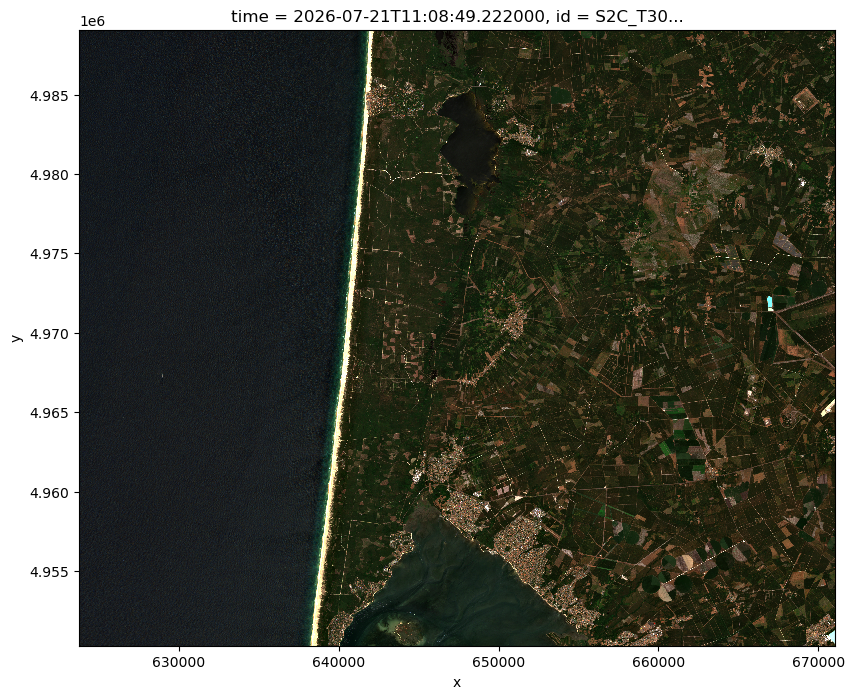

In [34]:
# plotting rgb image of aoi right before fire
rgb_cube = stackstac.stack(
    items, 
    assets=['red', 'green', 'blue'],
    resolution=10, 
    bounds_latlon=bbox, 
    epsg=epsg,
    xy_coords='center',
)
rgb_cube_before_after = load(xr.concat([before(rgb_cube), after(rgb_cube)], dim='time'))
rgb = rgb_cube_before_after.isel(time=0)

rgb.plot.imshow(rgb='band', vmin=0, vmax=0.3, size=8, aspect=rgb.sizes['x'] / rgb.sizes['y'])


/tmp/ipykernel_3985/1227604689.py:9: FutureWarning: In a future version of xarray the default value for coords will change from coords='different' to coords='minimal'. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set coords explicitly.
  false_color_cube_before_after = load(xr.concat([before(false_color_cube), after(false_color_cube)], dim='time'))


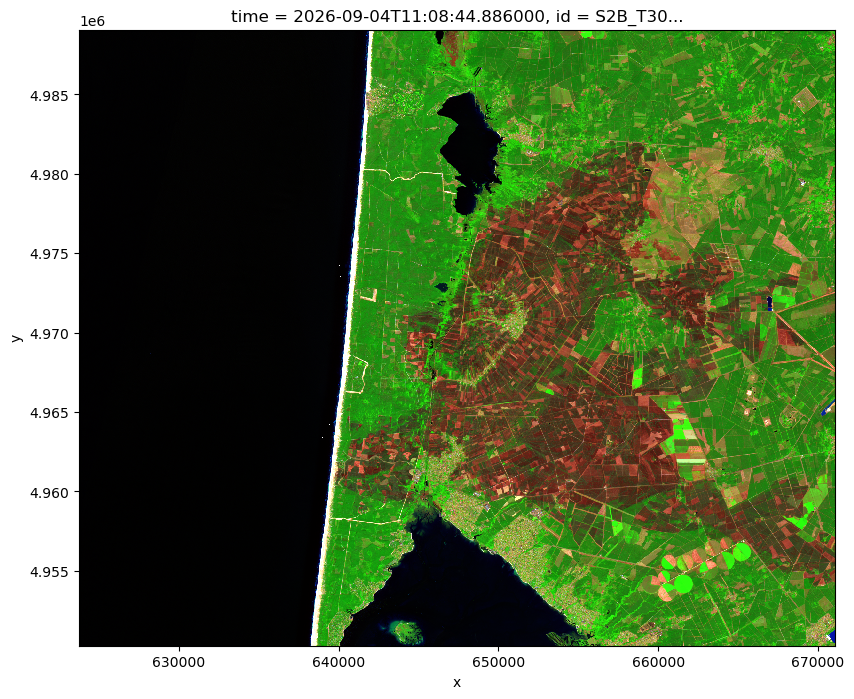

In [35]:
# plotting false color cube of aoi right after the fire
false_color_cube = stackstac.stack(
    items, assets=['swir22', 'nir08', 'red'],
    resolution=20,
    bounds_latlon=bbox,
    epsg=epsg,
    xy_coords='center',
)
false_color_cube_before_after = load(xr.concat([before(false_color_cube), after(false_color_cube)], dim='time'))
fcc = false_color_cube_before_after.isel(time=-1)

fcc.plot.imshow(rgb='band', vmin=0, vmax=0.4, size=8, aspect=fcc.sizes['x'] / fcc.sizes['y'])

In [36]:
cube = stackstac.stack(
    items, 
    assets=['nir08', 'swir22', 'scl'], 
    resolution=20, 
    bounds_latlon=bbox, 
    epsg=epsg,
    xy_coords='center',
)
cube = load(cube)

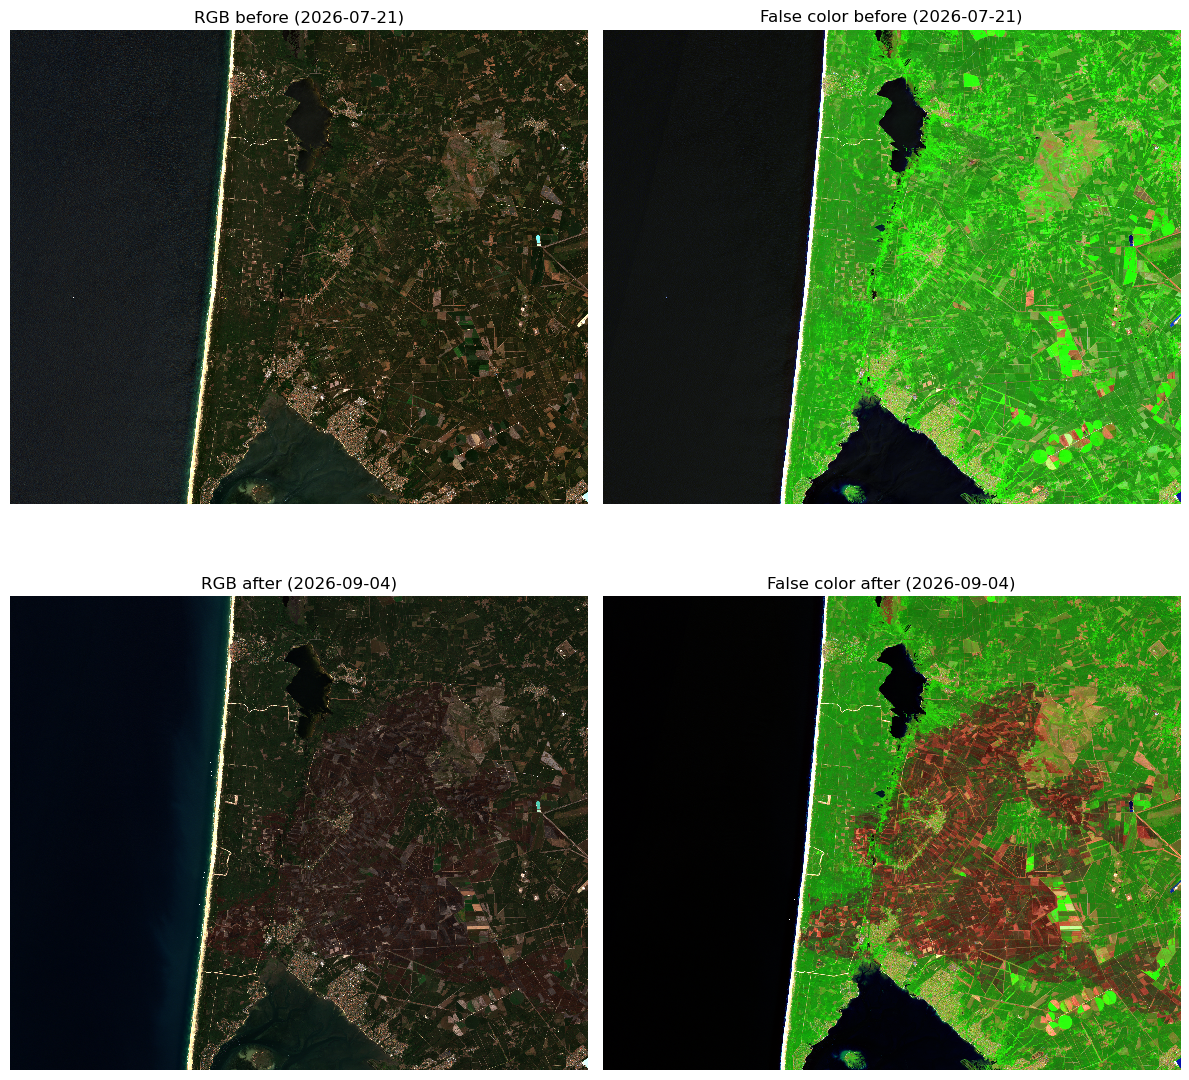

In [37]:
panels = [
    (rgb_cube_before_after.isel(time=0),             'RGB before',           0.3),
    (false_color_cube_before_after.isel(time=0),     'False color before',   0.4),
    (rgb_cube_before_after.isel(time=-1),            'RGB after',            0.3),
    (false_color_cube_before_after.isel(time=-1),    'False color after',    0.4),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 12))
for ax, (da, title, vmax) in zip(axes.flat, panels):
    da.plot.imshow(ax=ax, rgb='band', vmin=0, vmax=vmax)
    ax.set_title(f"{title} ({da.time.dt.strftime('%Y-%m-%d').item()})")
    ax.set_aspect('equal')
    ax.set_axis_off()
plt.tight_layout()

In [38]:
# calculating Normalized Burn Ratio

valid_classes = cube.sel(band='scl').isin([2, 4, 5, 7]) # dark areas, vegetation, bare soil, unclassified. Burn scars are often classified as any of these
nir = cube.sel(band='nir08').where(valid_classes)
swir = cube.sel(band='swir22').where(valid_classes)
nbr = (nir - swir) / (nir + swir)


In [39]:
# pre-fire nbr (first datetime  06-01-26)
pre = nbr.sel(time=slice(None, fire_start)).median('time') # gets the median nbr over all the dates before start of the fire to eliminate effects of clouds
post = nbr.sel(time=slice(fire_end, None)).median('time')
dnbr = pre - post
rbr = dnbr / (pre + 1.001)

burned_sq_mi = int((dnbr > 0.10). sum()) * 400 / 2589988 # 20m pixel = 400 sq m, 1 sq mile = 2,589,988 sq m

Text(0.5, 0.98, 'Burn analysis, 2026-07-21 to 2026-09-04')

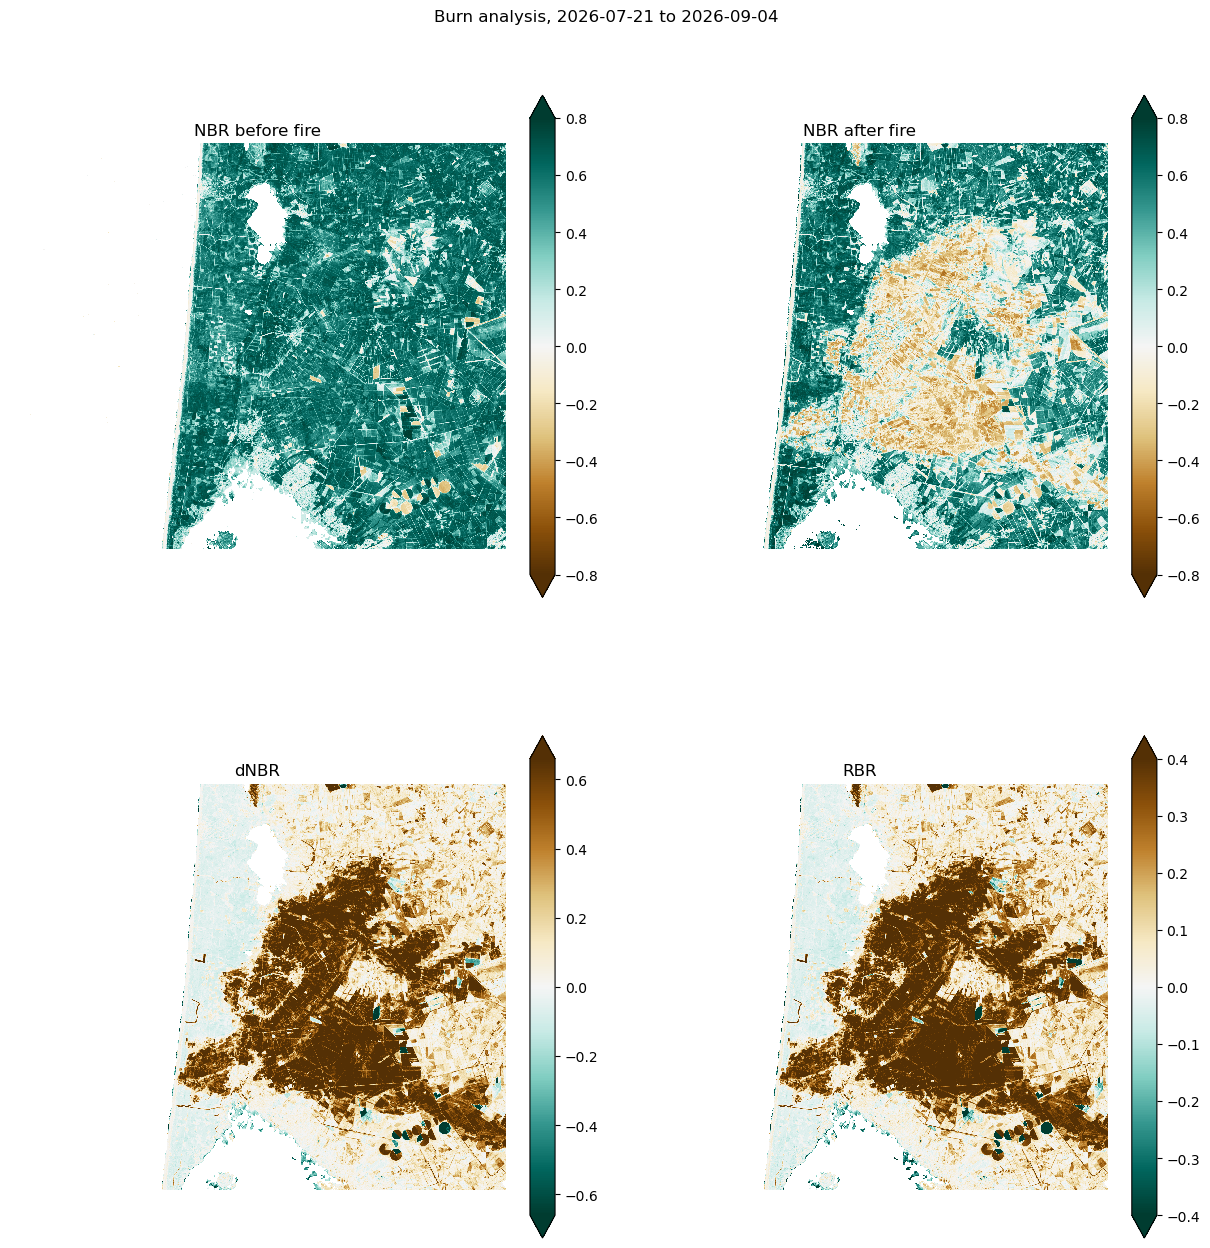

In [40]:
panels = [
    (pre,  'NBR before fire', 'BrBG',   0.8),
    (post, 'NBR after fire',  'BrBG',   0.8),
    (dnbr, 'dNBR',            'BrBG_r', 0.66),
    (rbr,  'RBR',             'BrBG_r', 0.4),
]
fig, axes = plt.subplots(2, 2, figsize=(12, 13), constrained_layout=True)
for ax, (da, title, cmap, lim) in zip(axes.flat, panels):
    da.plot.imshow(ax=ax, cmap=cmap, vmin=-lim, vmax=lim, cbar_kwargs={'shrink': 0.8, 'label': ''})
    ax.set_title(f'{title}')
    ax.set_aspect('equal')
    ax.set_axis_off()
fig.suptitle(f'Burn analysis, {fire_start} to {fire_end}')


In [41]:
# pre-fire nbr (first datetime  07-01-26)
pre2 = nbr.sel(time=slice('2026-07-01', fire_start)).median('time') # gets the median nbr over all the dates from 07-01-26 to right before start of the fire to eliminate effects of clouds
post2 = nbr.sel(time=slice(fire_end, None)).median('time')
dnbr2 = pre2 - post2
rbr2 = dnbr2 / (pre2 + 1.001)

burned_sq_mi2 = int((dnbr2 > 0.10). sum()) * 400 / 2589988 # 20m pixel = 400 sq m, 1 sq mile = 2,589,988 sq m

Text(0.5, 0.98, 'Burn analysis, 2026-07-21 to 2026-09-04')

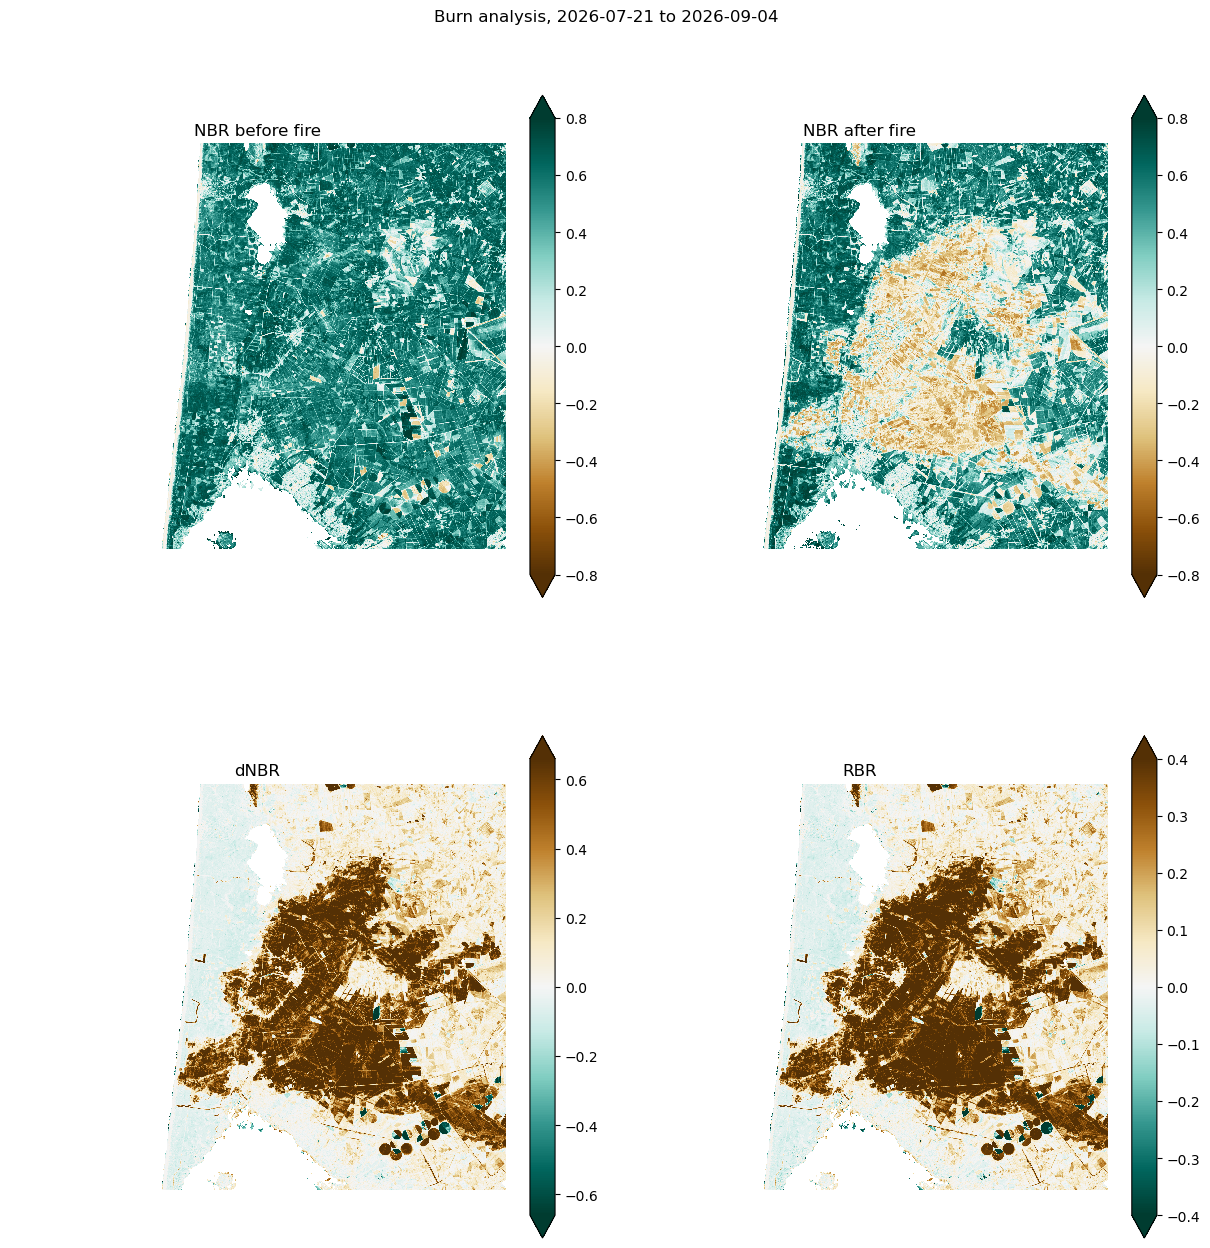

In [42]:
panels = [
    (pre2,  'NBR before fire', 'BrBG',   0.8),
    (post2, 'NBR after fire',  'BrBG',   0.8),
    (dnbr2, 'dNBR',            'BrBG_r', 0.66),
    (rbr2,  'RBR',             'BrBG_r', 0.4),
]
fig, axes = plt.subplots(2, 2, figsize=(12, 13), constrained_layout=True)
for ax, (da, title, cmap, lim) in zip(axes.flat, panels):
    da.plot.imshow(ax=ax, cmap=cmap, vmin=-lim, vmax=lim, cbar_kwargs={'shrink': 0.8, 'label': ''})
    ax.set_title(f'{title}')
    ax.set_aspect('equal')
    ax.set_axis_off()
fig.suptitle(f'Burn analysis, {fire_start} to {fire_end}')


In [43]:
no_of_prefire_scenes_july = len(nbr.sel(time=slice('07-01-2026', fire_start)).time)
print(no_of_prefire_scenes_july)

2


In [44]:
no_of_prefire_scenes_june = len(nbr.sel(time=slice(None, fire_start)).time)
print(no_of_prefire_scenes_june)

6


In [45]:
burned_sq_mi_june_minus_july = burned_sq_mi - burned_sq_mi2
print(burned_sq_mi_june_minus_july)

22.430374194783923


In [46]:
'''
Burn severity index table
--------------------------
dNBR	    Class	Meaning
< −0.25	        1	High regrowth
-0.25 to -0.10	2	Low regrowth
-0.10 to 0.10	3	Unburned
0.10 to 0.27	4	Low severity
0.27 to 0.44	5	Moderate-low severity
0.44 to 0.66	6	Moderate-high severity
>= 0.66	        7	High severity
'''

def to_cog(da, path, nodata):
    (da.reset_coords(drop=True)            # drop stackstac's extra metadata coords
       .rio.write_crs(f'EPSG:{epsg}')
       .rio.write_nodata(nodata)
       .rio.to_raster(path, driver='COG', compress='DEFLATE'))

to_cog(dnbr.astype('float32'), 'dnbr.tif', np.nan)
to_cog(rbr.astype('float32'), 'rbr.tif', np.nan)

# Key & Benson classes: 1-2 regrowth, 3 unburned, 4-7 low to high severity, 0 nodata
severity = xr.where(dnbr.isnull(), 0, # sets all null values to 0
                    np.digitize(dnbr, 
                    [-0.25, #   < −0.25 = 0
                     -0.10, #   -0.25 to -0.10 = 1
                     0.10, #    -0.10 to 0.10 = 2
                     0.27, #    0.10 to 0.27 = 3
                     0.44, #    0.27 to 0.44 = 4
                     0.66] #    0.44 to 0.66 = 5, >= 0.66 = 6
                     ) + 1).astype('uint8') # classes 1-7
to_cog(severity, 'severity.tif', 0)


In [47]:
severity.values

array([[0, 0, 0, ..., 4, 4, 4],
       [0, 0, 0, ..., 4, 4, 4],
       [0, 0, 0, ..., 4, 3, 4],
       ...,
       [0, 0, 0, ..., 4, 4, 4],
       [0, 0, 0, ..., 4, 4, 4],
       [0, 0, 0, ..., 4, 4, 4]], shape=(1940, 2364), dtype=uint8)

In [48]:
# convert square miles to pixels dynamically based on resolution
SQ_M_PER_SQ_MI = 2589988
MIN_PATCH_SQ_MI = 0.5 # setting minimum burn patch area of 0.5 sq mi

transform = severity.rio.transform()
px_sq_m = abs(transform.a * transform.e)                       # 20m × 20m = 400 m²
min_px = round(MIN_PATCH_SQ_MI * SQ_M_PER_SQ_MI / px_sq_m)     # 3,237 px

5 polygons, 144.86 sq mi burned


<Axes: >

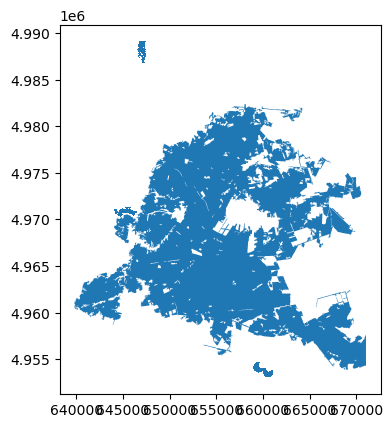

In [49]:
burned = (severity.values >= 5).astype('uint8') # dry farmland was classifying as severity level 4, so filtered for gte 5
# burned = sieve_until_stable(severity.values, size=3000)
burned = sieve_until_stable(burned, 25) # remove pixel-level speckle (25 px ~ 0.004 sq mi)
burned_gdf = gpd.GeoDataFrame(geometry=[
    shapely.geometry.shape(geom) 
    for geom, _ in rasterio.features.shapes(
        burned, 
        mask=burned == 1, 
        connectivity=8, 
        transform=transform)
        ], crs=epsg)
burned_gdf['area_sq_mi'] = burned_gdf.area / SQ_M_PER_SQ_MI
burned_gdf = burned_gdf[burned_gdf.area_sq_mi >= MIN_PATCH_SQ_MI].reset_index(drop=True)
burned_gdf.to_parquet('burned_area_binary_mask_patch_size_gte05sqmi.parquet')
print(f'{len(burned_gdf)} polygons, {burned_gdf.area_sq_mi.sum():.2f} sq mi burned')
burned_gdf.plot()


<Axes: >

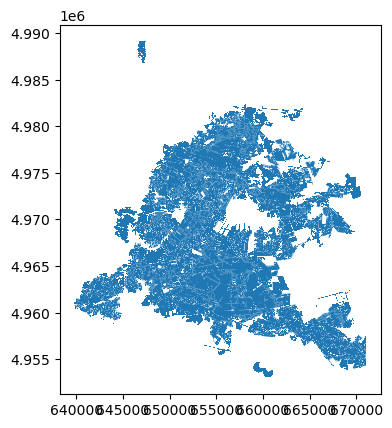

In [50]:
in_scar = rasterio.features.rasterize(
    burned_gdf.geometry, out_shape=burned.shape, transform=transform,
    fill=0, default_value=1, dtype='uint8',
) == 1
inside = np.where(in_scar, severity.values, 0).astype('uint8')
arr = sieve_until_stable(inside, size=25, mask=in_scar) # mask says that pixels outside the mask do not belong to any region and cannot be merged into
by_class = gpd.GeoDataFrame(
    [{'severity': int(v), 'geometry': shapely.geometry.shape(g)}
    for g, v in rasterio.features.shapes(
        arr, 
        mask=arr >= 5, 
        connectivity=8,
        transform=transform)],
    crs=epsg,
)
by_class.to_parquet('burned_area_by_class.parquet')
by_class.plot()